**Group 122, DRL Assignment I, Problem IV.**

The survey we reviewed (Bouneffouf and Rish, arXiv:1904.10040) reports no experiments, so we implemented representative bandit algorithms and measured cumulative (pseudo-)regret ourselves. This is an illustrative demonstration, not a reproduction of results from the survey.

- **Experiment A:** epsilon-greedy vs UCB1 vs Thompson Sampling on a stochastic Bernoulli bandit.
- **Experiment B:** LinUCB vs context-free UCB1 (and a uniform-random reference) on a linear-payoff contextual bandit.

Seeds are fixed, so re-running all cells gives the same numbers and figure. Run the cells top to bottom; the figure is shown inline and also saved as `regret_curves.png`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 122          # our group number
K = 10              # arms
T = 2000            # steps per run
RUNS_A = 500        # independent runs for experiment A
RUNS_B = 120        # independent runs for experiment B
D = 5               # context dimension for experiment B

In [2]:
def run_mab(policy, rng):
    """One run of a K-armed Bernoulli bandit. Returns cumulative expected regret."""
    mu = rng.uniform(0.0, 1.0, K)          # unknown true means (same for every policy given the seed)
    best = mu.max()
    counts = np.zeros(K)
    value = np.zeros(K)
    alpha = np.ones(K)                     # Beta(1,1) prior for Thompson
    beta = np.ones(K)
    regret = np.zeros(T)
    cum = 0.0

    for t in range(1, T + 1):
        if policy == "eps":
            a = rng.integers(K) if rng.random() < 0.1 else int(np.argmax(value))
        elif policy == "ucb1":
            if t <= K:
                a = t - 1
            else:
                a = int(np.argmax(value + np.sqrt(2.0 * np.log(t) / counts)))
        elif policy == "ts":
            a = int(np.argmax(rng.beta(alpha, beta)))

        r = 1.0 if rng.random() < mu[a] else 0.0
        counts[a] += 1
        value[a] += (r - value[a]) / counts[a]
        alpha[a] += r
        beta[a] += 1.0 - r

        cum += best - mu[a]                # expected (pseudo-)regret of this pull
        regret[t - 1] = cum
    return regret


def experiment_a():
    out = {}
    for policy in ("eps", "ucb1", "ts"):
        runs = np.array([run_mab(policy, np.random.default_rng(SEED + r)) for r in range(RUNS_A)])
        out[policy] = (runs.mean(0), runs.std(0, ddof=1) / np.sqrt(RUNS_A))   # mean, std. error
    return out

In [3]:
def run_contextual(policy, rng, alpha_ucb=0.6):
    """reward(a) = theta_a . x + noise, so the best arm depends on the context x."""
    theta = rng.normal(0, 1, (K, D))
    theta /= np.linalg.norm(theta, axis=1, keepdims=True)

    Ainv = np.array([np.eye(D) for _ in range(K)])   # LinUCB: inverse design matrix per arm
    b = np.zeros((K, D))
    counts = np.zeros(K)                             # context-free UCB1 state
    value = np.zeros(K)

    regret = np.zeros(T)
    cum = 0.0
    for t in range(1, T + 1):
        x = rng.normal(0, 1, D)
        x /= np.linalg.norm(x)
        true = theta @ x
        best = true.max()

        if policy == "linucb":
            p = np.empty(K)
            for a in range(K):
                th = Ainv[a] @ b[a]
                p[a] = th @ x + alpha_ucb * np.sqrt(x @ Ainv[a] @ x)
            a = int(np.argmax(p))
        elif policy == "ucb1":                        # context ignored
            if t <= K:
                a = t - 1
            else:
                a = int(np.argmax(value + np.sqrt(2.0 * np.log(t) / counts)))
        else:                                         # "random" reference
            a = int(rng.integers(K))

        r = true[a] + rng.normal(0, 0.1)
        v = Ainv[a] @ x                               # Sherman-Morrison rank-1 update (no inv per step)
        Ainv[a] -= np.outer(v, v) / (1.0 + x @ v)
        b[a] += r * x
        counts[a] += 1
        value[a] += (r - value[a]) / counts[a]

        cum += best - true[a]
        regret[t - 1] = cum
    return regret


def experiment_b():
    out = {}
    for policy in ("linucb", "ucb1", "random"):
        runs = np.array([run_contextual(policy, np.random.default_rng(SEED + 10000 + r))
                         for r in range(RUNS_B)])
        out[policy] = (runs.mean(0), runs.std(0, ddof=1) / np.sqrt(RUNS_B))
    return out

In [4]:
res_a = experiment_a()
res_b = experiment_b()

print(f"seed={SEED}  K={K}  T={T}  runsA={RUNS_A}  runsB={RUNS_B}  D={D}")
print("\nExperiment A - final cumulative regret at T=%d (mean +/- s.e.)" % T)
for k, (m, se) in res_a.items():
    print(f"  {k:<7}{m[-1]:8.1f} +/- {se[-1]:.1f}")
print("\nExperiment B - final cumulative regret at T=%d (mean +/- s.e.)" % T)
for k, (m, se) in res_b.items():
    print(f"  {k:<7}{m[-1]:8.1f} +/- {se[-1]:.1f}")

with open("results.txt", "w") as f:
    f.write(f"seed={SEED} K={K} T={T} runsA={RUNS_A} runsB={RUNS_B} D={D}\n")
    for k, (m, se) in res_a.items():
        f.write(f"A {k} final_regret {m[-1]:.2f} se {se[-1]:.2f}\n")
    for k, (m, se) in res_b.items():
        f.write(f"B {k} final_regret {m[-1]:.2f} se {se[-1]:.2f}\n")

seed=122  K=10  T=2000  runsA=500  runsB=120  D=5

Experiment A - final cumulative regret at T=2000 (mean +/- s.e.)
  eps       120.3 +/- 2.2
  ucb1      184.0 +/- 1.2
  ts         31.6 +/- 0.8

Experiment B - final cumulative regret at T=2000 (mean +/- s.e.)
  linucb     37.7 +/- 0.4
  ucb1     1328.8 +/- 4.5
  random   1326.3 +/- 4.6


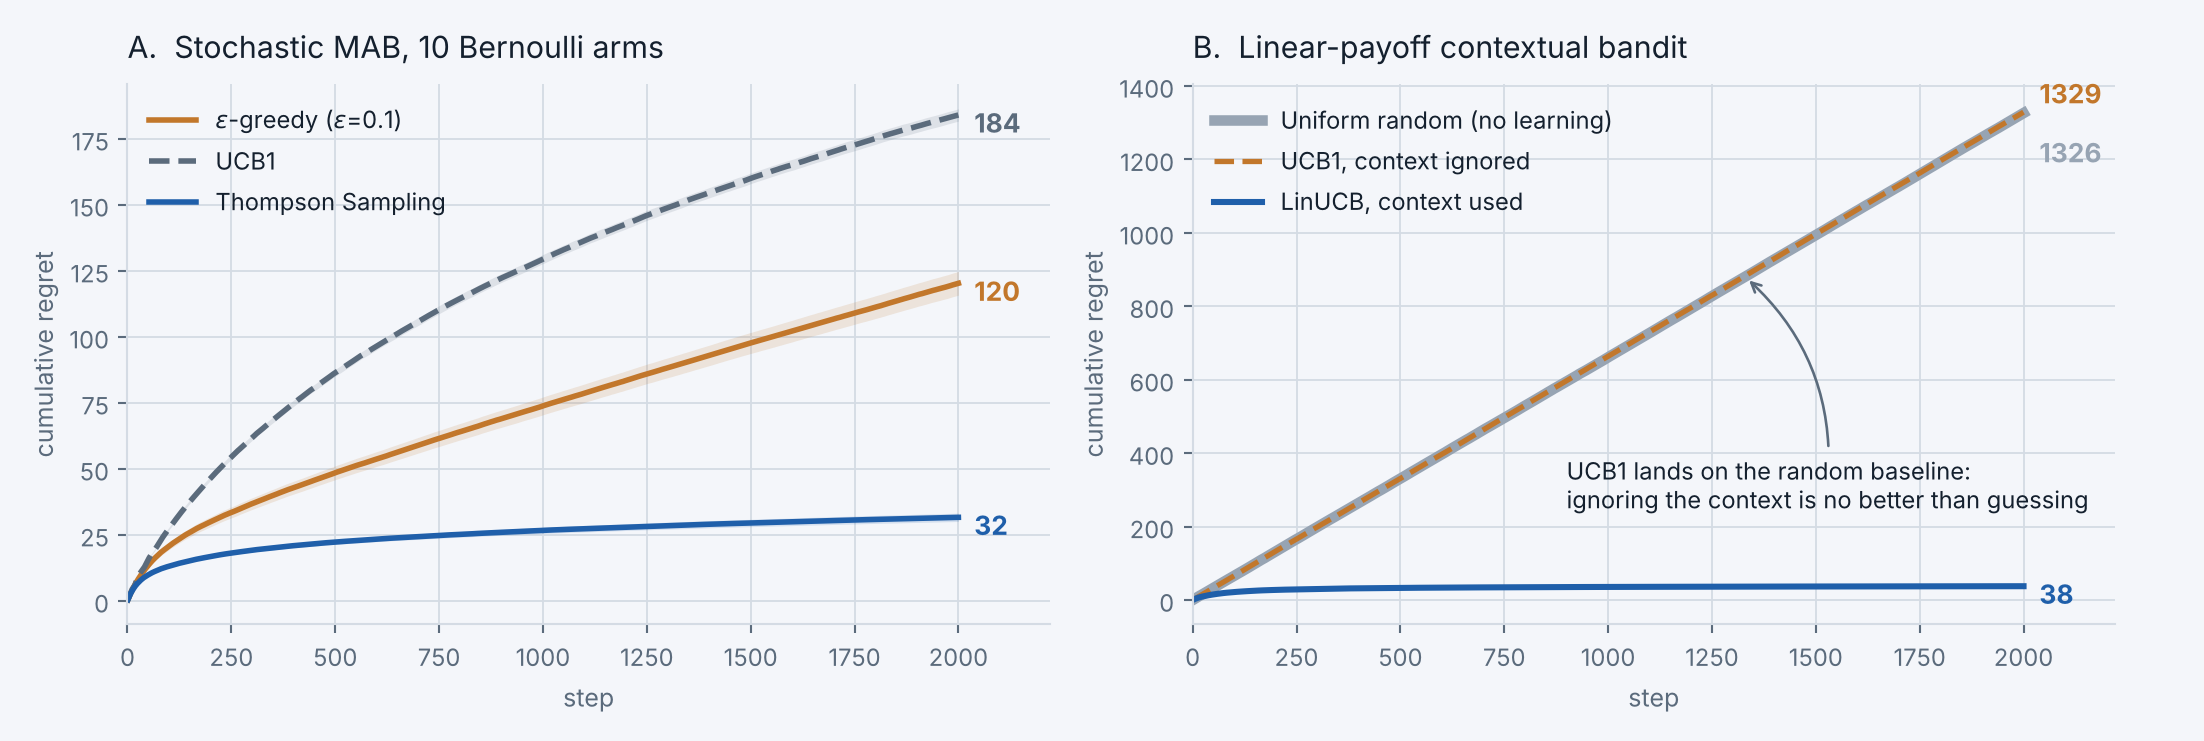

In [5]:
INK = "#14202E"; MUT = "#5B6B7C"; BLUE = "#1F5FAA"
PAPER = "#F4F6FA"; GRID = "#D4DBE4"; AMB = "#C2772B"; GREY = "#97A4B3"

fig, axes = plt.subplots(1, 2, figsize=(11.6, 3.9), facecolor=PAPER)
for ax in axes:
    ax.set_facecolor(PAPER)
    ax.grid(True, color=GRID, linewidth=0.7)
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    for sp in ("left", "bottom"):
        ax.spines[sp].set_color(GRID)
    ax.tick_params(colors=MUT, labelsize=9)

steps = np.arange(1, T + 1)

def draw(ax, res, order, title, label_offset=None):
    """order is a list of (key, (label, colour, linestyle, linewidth)) drawn in sequence,
    so an earlier, thicker curve stays visible under a later one that overlaps it."""
    for k, (lab, c, ls, lw) in order:
        m, se = res[k]
        ax.plot(steps, m, label=lab, color=c, linestyle=ls, linewidth=lw)
        ax.fill_between(steps, m - 2 * se, m + 2 * se, color=c, alpha=0.15, linewidth=0)
        off = (label_offset or {}).get(k, (6, -3))
        ax.annotate(f"{m[-1]:.0f}", (T, m[-1]), xytext=off, textcoords="offset points",
                    color=c, fontsize=10, fontweight="bold", va="center")
    ax.set_title(title, color=INK, fontsize=11.5, loc="left", pad=10)
    ax.set_xlabel("step", color=MUT, fontsize=9.5)
    ax.set_ylabel("cumulative regret", color=MUT, fontsize=9.5)
    ax.legend(frameon=False, fontsize=9, labelcolor=INK, loc="upper left")
    ax.set_xlim(0, T * 1.11)

draw(axes[0], res_a, [
    ("eps",  ("$\\epsilon$-greedy ($\\epsilon$=0.1)", AMB, "-", 2.1)),
    ("ucb1", ("UCB1", MUT, "--", 2.1)),
    ("ts",   ("Thompson Sampling", BLUE, "-", 2.1)),
], "A.  Stochastic MAB, 10 Bernoulli arms")

# Panel B: uniform random is drawn first and thick, so the UCB1 curve lying on top of it
# stays visible. The two coincide, which is the point of including the baseline.
draw(axes[1], res_b, [
    ("random", ("Uniform random (no learning)", GREY, "-", 4.0)),
    ("ucb1",   ("UCB1, context ignored", AMB, "--", 2.0)),
    ("linucb", ("LinUCB, context used", BLUE, "-", 2.3)),
], "B.  Linear-payoff contextual bandit",
   label_offset={"random": (6, -15), "ucb1": (6, 7)})

axes[1].annotate("UCB1 lands on the random baseline:\nignoring the context is no better than guessing",
                 xy=(1330, 880), xytext=(900, 250), fontsize=9, color=INK,
                 arrowprops=dict(arrowstyle="->", color=MUT, lw=1.0,
                                 connectionstyle="arc3,rad=0.25"))

plt.tight_layout()
plt.savefig("regret_curves.png", dpi=190, facecolor=PAPER)
plt.show()

## What we take from this

**Experiment A.** Thompson Sampling reaches 31.6 against UCB1's 184.0 on the same 500 problems. UCB1's bonus with c = sqrt(2) explores more than a 2000-step horizon rewards and its guarantee is asymptotic, so we report the ordering we measured rather than the one a textbook would predict.

**Experiment B.** Context-free UCB1 reaches 1328.8 and uniform random reaches 1326.3. The two are within one standard error of each other, so on this problem ignoring the context is no better than guessing. LinUCB, given the same data plus the context vector, flattens at 37.7.

**Caveat.** Both environments are synthetic. They test how the algorithms behave; they do not reproduce any domain result from the survey, because the survey reports none.